# Customizing Visualizations

Use **Code** cells to write and run any code you need to answer the question and **Markdown** cells to write out answers in words. After you are finished with the assignment, remember to download it as an **HTML file** and submit it in **ELMS**.

In [1]:
from requests import get

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter # for getting % formatted axes

%matplotlib inline

## Adjustments to Visualizations

Many times, we want to add more customizations to a visualization than just adding a title or labeling axes. This might include additional text or lines to clarify relationships, or changing the color scheme to make certain parts of the graph more clear. These can add to the visual appeal of the graph, but also add to the clarity and successful delivery of information. 

In this notebook, we will discuss some techniques to add features to graphs and make them look nicer while keeping in mind the elements that are key for a successful visualization. 

Let's start by bringing in some data that we can make plots with.

In [2]:
us_data =pd.read_csv('us_df.csv')
census_data = pd.read_csv('county_df.csv')

## Styles

So far, we have just been using the default style for graphs. For example, if we create a quick graph, it might look like this.

<AxesSubplot: >

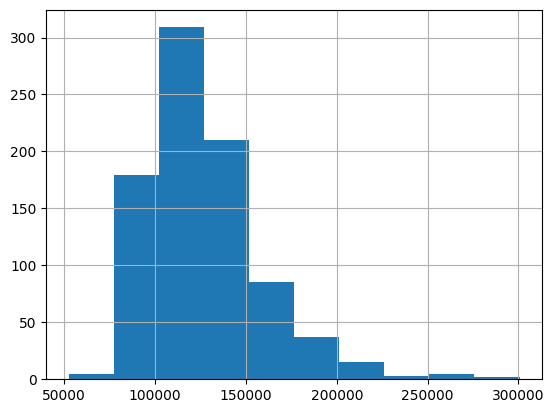

In [3]:
census_data.mean_income.hist()

One easy way to change the overall look of the graph is by trying out different styles. For example, you could use the default style used with ggplot, which is a visualization package first developed for R:

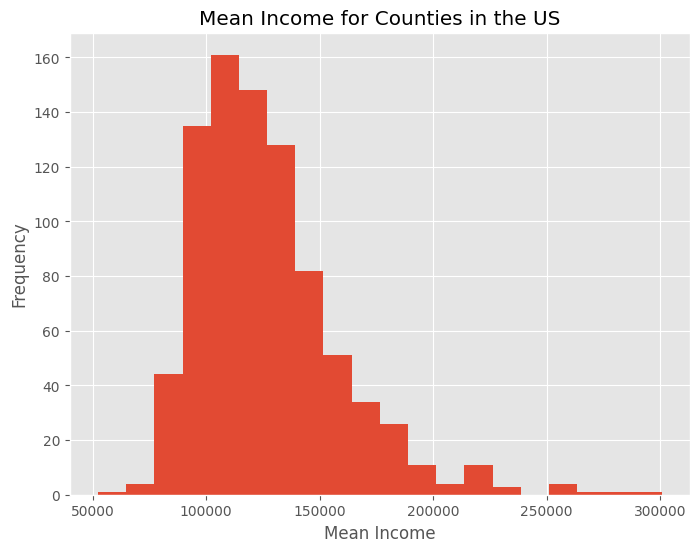

In [4]:
plt.style.use('ggplot')
fig, axes = plt.subplots(figsize=(8,6))
census_data.mean_income.hist(bins=20)
axes.set_xlabel("Mean Income")
axes.set_ylabel("Frequency")
axes.set_title("Mean Income for Counties in the US")
plt.show()

Alternatively, you could use the style used by FiveThirtyEight (https://fivethirtyeight.com/about-us/), which became popular for its use of graphics to show polling results as well as successful election predictions.

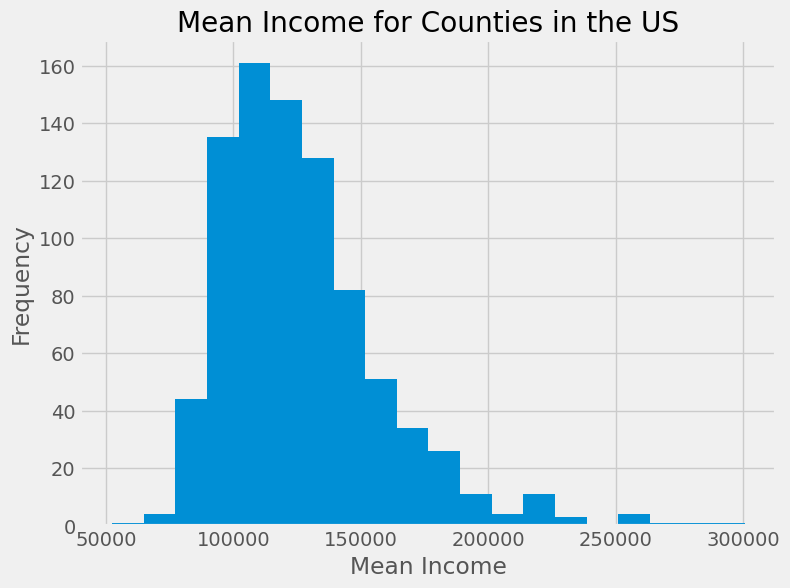

In [5]:
plt.style.use('fivethirtyeight')
fig, axes = plt.subplots(figsize=(8,6))
census_data.mean_income.hist(bins=20)
axes.set_xlabel("Mean Income")
axes.set_ylabel("Frequency")
axes.set_title("Mean Income for Counties in the US")
plt.show()

More plotting styles are provided in the matplotlib documentation here: https://matplotlib.org/stable/gallery/style_sheets/style_sheets_reference.html

## Adding Lines

Suppose we wanted to show what the overall US mean income value was on this histogram. We could do this by adding a line and adding a note about what that line represents. The `axvline` function adds a vertical line by providing the x value that it should be at, as well as providing some specifications for what that line should look like. The `color` argument adjusts the color, while `ls` adjusts the type of line. Since we want to distinguish it from the bars on the graph, we use red to contrast from the blue and make it dashed instead of solid. 

In [6]:
us_mean_income = us_data.mean_income[0]

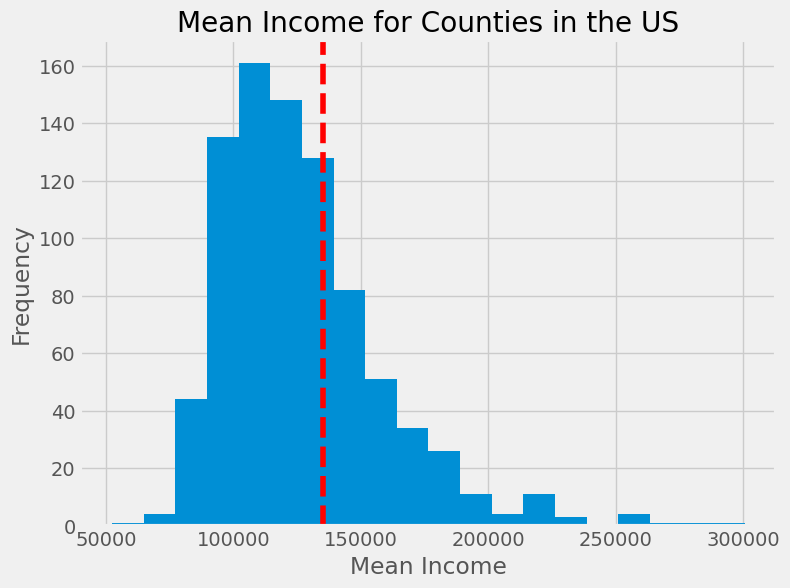

In [7]:
fig, axes = plt.subplots(figsize=(8,6))
census_data.mean_income.hist(bins=20)
axes.set_xlabel("Mean Income")
axes.set_ylabel("Frequency")
axes.set_title("Mean Income for Counties in the US")
plt.axvline(x = us_mean_income, color = 'red', ls = '--')
plt.show()

### Adding Annotations

The line might be helpful in identifying where the mean income for the US overall might be, but we can't tell what the value is exactly. In order to make it clear where that line is, we can add an annotation with the exact value. We use the `annotate` method to add the annotation on the Axes object. In the example below, we use f-strings to construct the exact text we want to put on the graph and specify the location of the text using the data coordinates. We want it a little bit offset from the actual mean so that the text isn't right on the line, so we add `5000` to the x-value of the location, then put it sufficiently high up so that it isn't running into any bars. 

Note that we use a slightly fancy f-string here as well. The `{us_mean_income:,}` means that it should insert the value in `us_mean_income` while using commas for every three digits, similar to how it might be shown when writing numbers in English. This makes it easier to read on the graph.

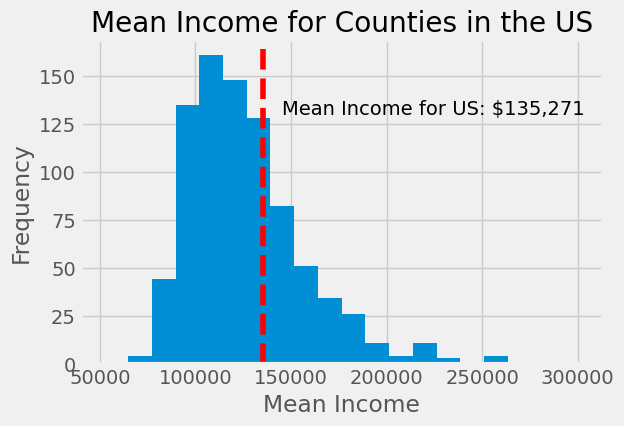

In [8]:
fig, axes = plt.subplots(figsize=(6,4))
census_data.mean_income.hist(bins=20)
axes.set_xlabel("Mean Income")
axes.set_ylabel("Frequency")
axes.set_title("Mean Income for Counties in the US")
plt.axvline(x = us_data.mean_income[0], color = 'red', ls = '--')
axes.annotate(f"Mean Income for US: ${us_mean_income:,}", 
              xy=(us_mean_income + 10000, 130), xycoords='data')
plt.show()

We also could have added the text using the figure coordinates by pixels or percentage of the full figure. For example, to add the text start halfway on the x-axis and 80% in height on the y-axis, we can use `xycoords = 'figure fraction'` with `xy=(0.5, 0.8)`. The `(0,0)` point is the bottom left, while `(1,1)` is on the top right. This might require a bit of fiddling around with the values to make sure it is in the right place.

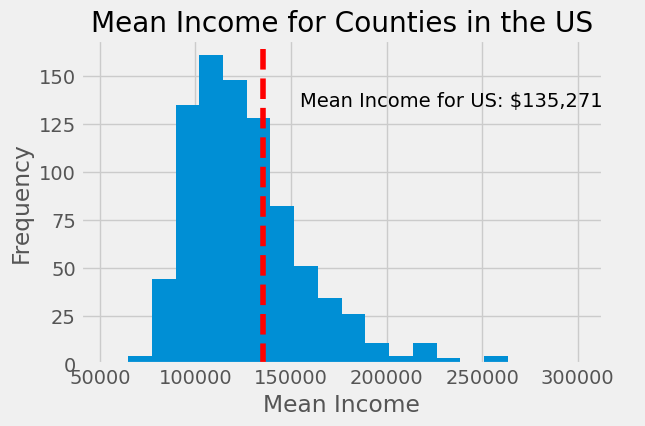

In [9]:
fig, axes = plt.subplots(figsize=(6,4))
census_data.mean_income.hist(bins=20)
axes.set_xlabel("Mean Income")
axes.set_ylabel("Frequency")
axes.set_title("Mean Income for Counties in the US")
plt.axvline(x = us_data.mean_income[0], color = 'red', ls = '--')
axes.annotate(f"Mean Income for US: ${us_mean_income:,}", 
              xy=(0.5, 0.8), xycoords='figure fraction')
plt.show()

We might want to make it a bit more clearer that this line represents the mean, too. That is, we might want to draw an arrow that indicates that the text is describing that line. To do this, we can add arguments to the `annotate` method to have it draw an arrow and give it where the arrow should be pointing. The `xy` argument indicates where on the graph the arrow should be pointing, and the `xytext` argument indicates where on the graph the text should be. An arrow will then be drawn from the text to the point in `xy`. 

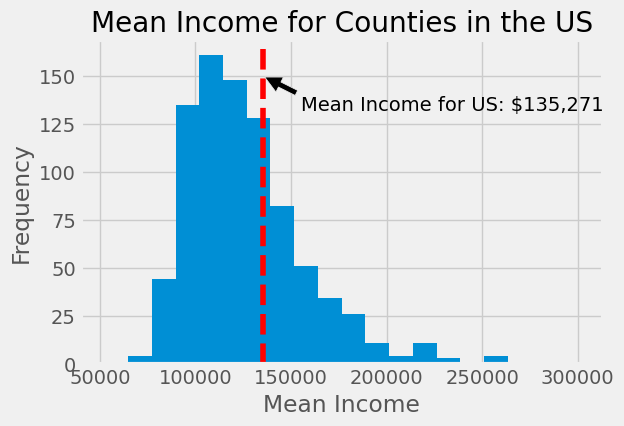

In [10]:
fig, axes = plt.subplots(figsize=(6,4))
census_data.mean_income.hist(bins=20)
axes.set_xlabel("Mean Income")
axes.set_ylabel("Frequency")
axes.set_title("Mean Income for Counties in the US")
plt.axvline(x = us_data.mean_income[0], color = 'red', ls = '--')
axes.annotate(f"Mean Income for US: ${us_mean_income:,}", 
              xy=(us_mean_income, 150), xycoords='data',
             xytext = (us_mean_income + 20000, 140), textcoords = 'data',
             arrowprops=dict(facecolor='black', shrink=0.05),
             horizontalalignment='left', verticalalignment='top')
plt.show()

<font color ='red'>**Question 1: Consider the scatterplot shown below. Add an annotation to show the county name of the point with the highest percent of people with a bachelor's degree as well as the lowest percent of people with a bachelor's degree.**</font>

## Adjusting Categories 

Sometimes, when you make a graph with a categorical variables, the order of the categories gets mixed around and isn't really in a sensical order. This happens most often with **ordinal** variables, in which the values of the categorical variables are ordered in some way (for example, something like shirt size with small, medium, and large). 

Let's take a look at some categorical variables from the 2024 round of the American National Election study.

In [12]:
data_file = "anes24_sample.csv"
df = pd.read_csv(data_file)
df.head()

,id,age,age_group,gender,race,education,partyid,libcon,fo_dei,fo_jus_soli,...,harris_dislikes,trump_likes,trump_dislikes,mipp_1,harris_therm,trump_therm,born_again,better_off,pre_weight,post_weight
0,140001,50.0,45-54,1. Man,3. Hispanic,4. Bachelor's degree,7. Strong Republican,6. Conservative,7. Oppose a great deal,6. Oppose moderately,...,She has had 3 1/2 yrs to make things better an...,look at the cost of everything I stated before...,NaN,immigration we can't take care of our own peop...,0.0,85.0,1. Yes,4. Somewhat worse off,0.809064,0.780975
1,140002,41.0,35-44,2. Woman,4. Asian or Native Hawaiian/other Pacific Isla...,"3. Some post-high school, no bachelor's degree",4. Independent,4. Moderate; middle of the road,4. Neither favor nor oppose,4. Neither favor nor oppose,...,NaN,NaN,NaN,"The cost of everything, people can not afford ...",50.0,50.0,-1. Inapplicable,4. Somewhat worse off,2.575472,2.507075
2,140003,44.0,35-44,2. Woman,"1. White, non-Hispanic","3. Some post-high school, no bachelor's degree",1. Strong Democrat,2. Liberal,4. Neither favor nor oppose,7. Oppose a great deal,...,NaN,NaN,I disagree with him on literally EVERYTHING. H...,threats to democracy,85.0,0.0,-1. Inapplicable,3. About the same,0.798864,0.814401
3,140004,45.0,45-54,1. Man,4. Asian or Native Hawaiian/other Pacific Isla...,"3. Some post-high school, no bachelor's degree",6. Not very strong Republican,99. Haven't thought much about this,6. Oppose a moderate amount,6. Oppose moderately,...,NaN,strong personality,NaN,economy and leadership.,85.0,NaN,2. No,3. About the same,0.244757,0.263490
4,140005,80.0,NaN,1. Man,"1. White, non-Hispanic",5. Graduate degree,5. Independent-Republican,4. Moderate; middle of the road,6. Oppose a moderate amount,2. Favor moderately,...,"Economy, border security, killing private insu...","economy, border security, keep my insurance, g...","bio weapon injections, spending,","Economy, Border,",0.0,60.0,-1. Inapplicable,4. Somewhat worse off,0.239209,0.216673


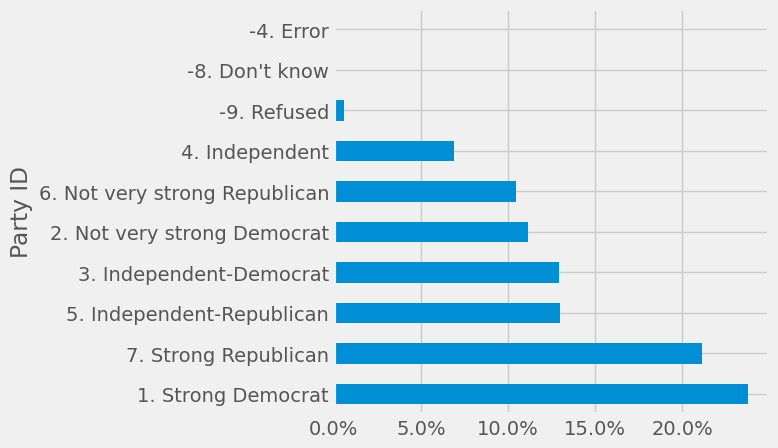

In [13]:
fig, axes = plt.subplots(figsize=(5,5))
df.partyid.value_counts(normalize=True).plot.barh(ax=axes)
axes.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
axes.set_ylabel("Party ID")
plt.show()

This graph organizes the values in increasing order, but it can be a bit confusing to try to get an idea of the overall spectrum of political parties because the Republican and Democrat categories are all mixed up. It also includes several dk/refusal responses that might be better to either drop or combine in a single group. Finally, the labels are a bit long and might be easier to work with if I shortened them.

I'll use a dictionary to remap the old labels to new, shorter ones, and then I'll apply this using the `map` function. Note that my dictionary leaves out the invalid responses entirely, so these are going to be ignored when I create my bar plot.

In [14]:
partyid_map = {"1. Strong Democrat": "Str. Dem.",
               "2. Not very strong Democrat": "Wk. Dem.",
               "3. Independent-Democrat": "Ind. Dem.",
               "4. Independent": "Ind.", 
               "5. Independent-Republican": "Ind. Rep.",
               "6. Not very strong Republican": "Wk. Rep.",
               "7. Strong Republican": "Str. Rep."
}
pid = df['partyid'].map(partyid_map)

# checking the results:
pid[:5]

0    Str. Rep.
1         Ind.
2    Str. Dem.
3     Wk. Rep.
4    Ind. Rep.
Name: partyid, dtype: object

Then, I'll convert the result to a "categorical" data type using `pd.Categorical`. The `categories` argument of `pd.Categorical` allows me to set a specific ordering for my categorical variables, so I'll use the `partyid_map.values()` to cause the ordering of `pid_recode` to match the order of may new value labels in `partyid_map`:



In [18]:
df['pid_recode'] = pd.Categorical(pid, categories=partyid_map.values())
df['pid_recode'].value_counts(sort=False)

Str. Dem.    1314
Wk. Dem.      616
Ind. Dem.     714
Ind.          380
Ind. Rep.     716
Wk. Rep.      577
Str. Rep.    1166
Name: pid_recode, dtype: int64

Now I'll recreate my bar plot using the `pid_recode` variable I just created:

In [ ]:
fig, axes = plt.subplots(figsize=(5,5))
df.pid_recode.value_counts(normalize=True, sort=False).plot.barh(ax=axes)
axes.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
axes.set_ylabel("Party ID")
plt.show()

<font color ='red'>**Question 2: Create a bar graph of the education level for the ANES data. Make sure it is in a reasonable order and has readable labels. Be sure to include appropriate labels and a title for the plot**</font>

## Using colors

The plotting defaults typically provide colors that work well for a given graph. However, sometimes, you might want to adjust these colors to better represent the data. This is often pertinent when using an ordinal variable, especially for a variable like political party, where a standard color is associated with the groups (blue for Democrats, red for Republicans). The default colors might be misleading in these cases, so it would be good to set our own colors. Let's take a look at an example by comparing political party by gender in the Pulse of the Nation dataset.

Recall that we used `pd.crosstab` to look at comparisons of two categorical variables, with the `normalize` argument allowing us to get proportions rather than raw numbers.

In [ ]:
df.gender.value_counts()

In [ ]:
gender_map = {'1. Man':'Man', '2. Woman':'Woman', '3. Nonbinary' : 'Non-binary/Other', '4. Something else, please specify': 'Non-binary/Other'}

df['gender_3cat'] = pd.Categorical(df.gender.map(gender_map), categories= ['Woman', "Man", "Non-binary/Other"])

In [ ]:

party_by_gender = pd.crosstab(df.gender_3cat,df.pid_recode, normalize='index')
party_by_gender

We will create a stacked bar chart so that we can look at the comparisons of proportions across genders. To create a stacked chart, we just need to add the `stacked = True` option when we create our horizontal barplot:

In [ ]:
fig, axes = plt.subplots(figsize=(11,3))
party_by_gender.plot.barh(stacked = True, ax = axes)
axes.set_ylabel('Gender')
axes.set_xlabel("Proportion")
axes.set_title("Party ID by gender")
axes.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
plt.show()

There are a lot of things that we need to fix with this graph! First, as mentioned before, the colors are very confusing. Blue does not correspond to Democrats, nor does the color that is closest to red correspond to Republicans. Moreover, the legend is covering up part of the graph, making this harder to read.

We'll move the legend by using the `.legend()` method with the `bbox_to_anchor` argument providing a way for us to adjust the location. The `ncol = 7` argument makes it so that the categories are displaying horizontally (7 categories = 7 columns)

In [ ]:
fig, axes = plt.subplots(figsize=(11,3))
party_by_gender.plot.barh(stacked = True, ax = axes)
axes.set_ylabel('Gender')
axes.set_xlabel("")
axes.set_title("Party ID by gender")
axes.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
axes.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=7)
# axes.legend(loc='lower center', bbox_to_anchor=(1.2, .4), ncol=1) # or run this to align the legend on the right
plt.show()

We still have an issue with the colors. We'd like to adjust these to better represent the parties. To do this, we can use the `color` argument within `barh` so that we assign colors to the seven categories. This can be done using a myriad of methods, such as specifying hex RGB values or using existing named colors. Here, we simply use the names, but you can check the matplotlib color section to see other ways of specifying colors here: https://matplotlib.org/stable/gallery/color/color_demo.html. 

A list of named colors can be found here: https://matplotlib.org/stable/gallery/color/named_colors.html.

(Note that I also added some black lines around each section of each barplot with `edgecolor='black'` and I made some adjustments to the gridlines here by modifying `axes.grid`)

In [ ]:
color_scheme = ['blue','royalblue','powderblue', 'grey','rosybrown','indianred','red'] # attempting to make a gradient from blue to red
fig, axes = plt.subplots(figsize=(11,3))
party_by_gender.plot.barh(stacked = True, 
                          ax = axes, 
                          color = color_scheme, 
                          edgecolor='black') # adding black edges around each box

axes.set_ylabel('Gender')
axes.set_xlabel("")
axes.set_title("Party ID by gender")
axes.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
axes.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=7)
# adding only the verticle gridlines (horizontal lines aren't helpful here)
axes.grid(False)
axes.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


We could also try creating a custom color map that can be automatically applied to our bar plot. The code below creates a "colormap" that ranges "blue" to "gray" to "red":

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

colors = ["blue",'grey', 'red']
bgr_map = LinearSegmentedColormap.from_list("mycmap", colors)
bgr_map

I can pass `bgr_map` to the `cmap` argument of `plot.barh` to use that mapping in my plot:

In [ ]:
fig, axes = plt.subplots(figsize=(11,3))
party_by_gender.plot.barh(stacked = True, 
                          ax = axes, 
                          cmap  = bgr_map, 
                          edgecolor='black')

axes.set_ylabel('Gender')
axes.set_xlabel("")
axes.set_title("Party ID by gender")
axes.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
axes.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=7)
axes.grid(False)
axes.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

<font color ='red'>**Question 3: Create a visualization that looks at the relationship between the `fo_schoolvax` (favor or oppose vaccine mandates in schools) variable across levels of the education variable. Make sure you adjust colors and reorder variables as appropriate. Does it look like there is a relationship?**</font>

# Seaborn

While `matplotlib` can be very useful for creating graphs, it can be easy to get bogged down in all of the intricacies of customizing everything you want to do. In this section, we introduce a few other plotting libraries that you can use to make graphs. We only show a few examples of doing simple histograms and boxplots here, because there are lots and lots of possibilities for visualizations, so we don't want to spend too much time on going every single little detail here. Instead, these are meant to show a little bit about the syntax and style of the graphs that are produced so that you can learn more about them on your own if you'd like.


In [ ]:
import seaborn as sns

In [ ]:
sns.displot(data = df, x = 'harris_therm')

In [ ]:
g = sns.displot(data = df, x = 'harris_therm')
g.set(xlabel = 'Kamala Harris feeling thermometer', title = 'Views of Kamala Harris ANES respondents in 2024')
plt.xticks([20, 40, 60, 80, 100])
plt.show()

In seaborn, you can use figure-level functions (`relplot`, `displot`, or `catplot`) or axes-level functions (see subcategories below). 

![](https://seaborn.pydata.org/_images/function_overview_8_0.png)

Seaborn plots are particularly useful when we want to create comparisons across groups. For instance, if I wanted to see values of `harris_therm` across different levels of `pid_recode` I could use

In [ ]:
g = sns.catplot(data =df, y='harris_therm', x='pid_recode', kind='violin', aspect=2)
g.set_xlabels("Trump Feeling thermometer")
g.set_ylabels("Party ID")

Anything that you can do in Seaborn can also be done in matplot, but Seaborn has some sensible default settings that allow you to make complicated plots with a lot less code. Here, I'm creating comparing the average Trump feelings among black and white respondents who do or do not consider themselves "born again":

In [ ]:
race_map = {'1. White, non-Hispanic' : "White", '2. Black, non-Hispanic': "Black"}
born_again_map = {'1. Yes': "Yes", "2. No" : "No"} 
df['race_2cat'] = df['race'].map(race_map)
df['born_again_2cat']  =df['born_again'].map(born_again_map)

g=sns.catplot(data = df, 
              x = 'race_2cat', 
              y = 'trump_therm',  # trump thermometer
              hue = 'born_again_2cat',  # colored by race
              kind = 'point',  # creates a line plot with points for each category
              aspect=3,     # 3 times as wide as tall
              markersize=10, 
              linewidth=5)
g.set(ylabel = 'Trump feelings', xlabel='Race',  title = 'Trump feeling thermometer by race and born again.')
g.legend.set_title("Consider self born again?") # Accessing the legend object directly

Moreover, Seaborn makes it relatively easy to create faceted plots that show relationships separately across multiple groups. 

In [ ]:
md_va = census_data[(census_data.state == 'Maryland') | (census_data.state == 'Virginia')]

In [ ]:
g = sns.relplot(
    data=md_va,
    x="percent_bachelors", y="mean_income", col="state",
    size="num_households"
)

# Set axis labels
g.set_axis_labels("Percent Bachelor's", "Mean Income")

# Add overall Title
g.figure.subplots_adjust(top=.85)
g.figure.suptitle("Percent Bachelor's by Mean Income for MD and VA")
g._legend.set_title('Num. households')

Or create plots with a regression model:

In [ ]:
g = sns.lmplot(
    data = md_va,
    x = "percent_bachelors", y = "mean_income",
    hue = "state"
)
g.set(xlabel = "Percent Bachelor's", ylabel = "Mean Income", 
      title = "Mean Income by Percent Bachelor's \nfor Counties in MD vs VA (2022)")

In [ ]:
md_va.loc[:, md_va.columns.str.startswith('percent')]

Or show the relationship between multiple numeric variables in a single plot

In [ ]:
percent_cols = md_va.loc[:, md_va.columns.str.startswith('percent')].copy()
percent_cols['state'] = md_va['state']
g = sns.pairplot(percent_cols, hue='state')
g.figure.set_size_inches(20, 20)
g.figure.suptitle( "Census data for Counties in MD vs VA (2022)")
plt.show()

Or create a heatmap from a correlation matrix:

In [ ]:
corr = census_data.loc[:, 'num_households':'percent_broadband'].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr,
            mask = mask, 
            cmap='coolwarm',
            vmin=-1, 
            vmax=1, 
            center=0,
            square=True, 
            linewidths=.5, 
            cbar_kws={"shrink": .5}
              )